In [1]:
import os
import random
import sys
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as transforms
import torchvision.transforms.functional as TF
from pathlib import Path
from torch import optim
from torch.utils.data import DataLoader, random_split
from tqdm import tqdm

# import wandb
from evaluate import evaluate
from unet import UNet

# from utils.dice_score import dice_loss, multiclass_dice_coeff

import numpy as np
import matplotlib.pyplot as plt

In [2]:
from fakeionogramdatasetFOF2 import ParabolaIonoDatasetOX


In [3]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(device)

cuda:0


In [4]:
from torch.optim import Adam

epochs = 5
batch_size = 5
learning_rate = 3e-3
val_percent = 0.1

weight_decay = 1e-8
momentum = 0.2
gradient_clipping = 1.0
       
dataset = ParabolaIonoDatasetOX('training_data_parabola_fof2')

n_val = int(len(dataset) * val_percent)
n_train = len(dataset) - n_val
train_set, val_set = random_split(dataset, [n_train, n_val], generator=torch.Generator().manual_seed(0))

d = np.load('JM91J_2016014141141.npy', allow_pickle=True)[()]
freqs = d['vipir_freqs']
freqs_torch = torch.vstack([torch.from_numpy(freqs)]*batch_size)
# 3. Create data loaders
loader_args = dict(batch_size=batch_size, num_workers=8, pin_memory=True) #os.cpu_count()

train_loader = DataLoader(train_set, shuffle=True, **loader_args)
val_loader = DataLoader(val_set, shuffle=True, drop_last=True, **loader_args)

/home/linle2/.local/lib/python3.11/site-packages/torchvision/transforms/functional.py:1603: UserWarning: The default value of the antialias parameter of all the resizing transforms (Resize(), RandomResizedCrop(), etc.) will change from None to True in v0.17, in order to be consistent across the PIL and Tensor backends. To suppress this warning, directly pass antialias=True (recommended, future default), antialias=None (current default, which means False for Tensors and True for PIL), or antialias=False (only works on Tensors - PIL will still use antialiasing). This also applies if you are using the inference transforms from the models weights: update the call to weights.transforms(antialias=True).
  warnings.warn(


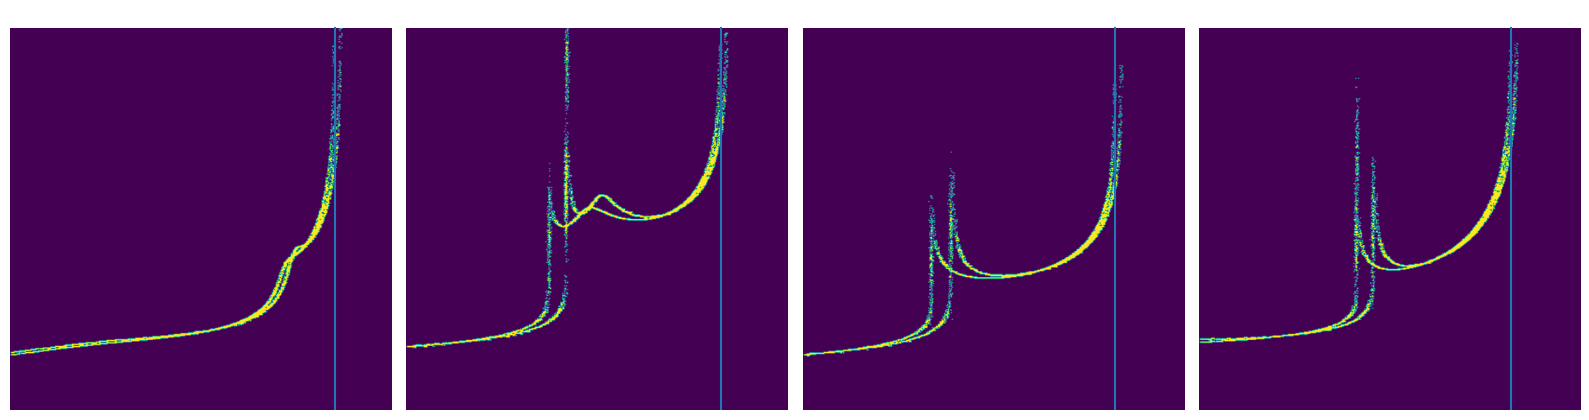

In [5]:
# visualize the training set

fig, axs = plt.subplots(ncols=4, nrows=1, figsize=(16, 12))
for idx, ax_i in enumerate(axs.T):
    target = train_set[idx]
    img = target["image"]
    # gt = target["mask"]
    ax = ax_i
    img = img.permute((1, 2, 0)).numpy()
    ax.imshow((img * 255).astype(np.uint8), origin = 'lower')
    ax.axis('off')

    fof2 = target["asymfO"]
    ifof2 = np.argmin(np.abs(freqs - fof2)) / freqs.shape[0] * 572
    ax.plot([ifof2,ifof2],[0,572])
    # ax = ax_i[1]
    # gt = gt.numpy()
    # ax.imshow((gt[0,:,:]*122).astype(np.uint8), origin = 'lower')
    # ax.axis('off')
    # ax = ax_i[2]
    # ax.imshow((gt[1,:,:]*122).astype(np.uint8), origin = 'lower')
    # ax.axis('off')
fig.tight_layout()


In [6]:
class DBCEF(nn.Module):
    """ DBCEF from paper https://arxiv.org/pdf/1906.05229 """

    def __init__(self, epsilon: float = 1e-4, gamma: float = 1):
        super().__init__()
        self.softmax = nn.Softmax(dim=1)
        self.epsilon = epsilon
        self.gamma = gamma

    def forward(self, input : torch.Tensor, target : torch.Tensor):
        # assert input.dim() == 3 or input.dim() == 4
        x = self.softmax(input)
        t = nn.functional.one_hot(target).permute(0, 3, 1, 2).contiguous()

        N = t.size()[0]*t.size()[1]
        beta = (torch.sum(t,dim=(-1,-2))/N)[:,:,None,None]

        FCE = (1-x)**self.gamma*t*torch.log(x)
        FCE = FCE/(beta+self.epsilon)

        return -1*FCE.sum()/N/input.size()[0]
    

In [7]:
class fof2Net(nn.Module):
    def __init__(self):
        super(fof2Net, self).__init__()
        self.fc1 = nn.Linear(572*572, 572)

    def forward(self, x):
        x = torch.flatten(x, 1)
        x = self.fc1(x)
        return x

In [8]:
model = UNet(n_channels=1, n_classes=5, bilinear=False)
model.load_state_dict(torch.load('path_to_save_model_newloss/'+'checkpoint_epoch_5.pth')['model_state_dict'])
model = model.to(device=device)
model.eval()

fmodel = fof2Net()
fmodel = fmodel.to(device=device)


In [9]:
# sigmoid = nn.Sigmoid()
optimizer = Adam(fmodel.parameters(), lr=learning_rate)
# optimizer = optimizer.to(device=device)
dbcefloss = DBCEF()
dbcefloss = dbcefloss.to(device=device)

criterion = nn.CrossEntropyLoss()

In [11]:
losses = []
val_losses = []
for epoch in range(1,epochs):
    # model.train()

    with tqdm(total=n_train, desc=f'Epoch {epoch+1}/{epochs}', unit='img') as pbar:
        running_loss = 0.0
        for i, data in enumerate(train_loader, 0):
            inputs = data['image']
            fof2 = data['asymfO']
            ifof2 = torch.argmin(torch.abs(freqs_torch - fof2[:,None]),dim = -1) / freqs.shape[0] * 572
            inputs = inputs.to(device)
            ifof2 = ifof2.to(device, dtype=torch.long)
            optimizer.zero_grad()
            outputs = model(inputs)
            # loss = dbcefloss(outputs[:,0:2,:,:], labels[:,0,:,:]) + dbcefloss(outputs[:,2:4,:,:], labels[:,1,:,:])
            fof2_pred = fmodel(outputs[:,4,:,:])
            loss = criterion(fof2_pred, ifof2)
            loss.backward()
            optimizer.step()
            running_loss += loss
            pbar.update(inputs.shape[0])
            pbar.set_postfix(**{'loss (batch)': loss.item()})
            
        avg_loss = running_loss / len(train_loader)
        losses.append(avg_loss)
        print(f'Epoch: {epoch + 1}, Loss: {avg_loss:.4f}')
        print('-' * 20)
        
        if not os.path.exists('path_to_save_model'):
            os.makedirs('path_to_save_model')

        torch.save({
                'epoch': epoch,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'loss': loss,
                }, f'path_to_save_model_newloss/checkpoint_epoch_fmodel_{epoch + 1}.pth')
    
        model.eval()
        val_loss = 0
        with torch.no_grad():
            for i, data in enumerate(val_loader, 0):
                inputs = data['image']
                fof2 = data['asymfO']
                ifof2 = torch.argmin(torch.abs(freqs_torch - fof2[:,None]),dim = -1) / freqs.shape[0] * 572
                inputs = inputs.to(device)
                ifof2 = ifof2.to(device, dtype=torch.long)
                fof2_pred = fmodel(outputs[:,4,:,:])
                loss = criterion(fof2_pred, ifof2)
                val_loss += loss
            avg_val_loss = val_loss / len(val_loader)
            val_losses.append(avg_val_loss)
            print(f'Validation Loss: {avg_val_loss:.4f}')

            # randomly select a validation data to plot its predicted vs actual curve
            # rand_index = torch.randint(len(val_loader.dataset), size=(1,)).item()
            # random_data = val_loader.dataset[rand_index]
            # random_input, actual_params = random_data
            # random_input = random_input.to(device).unsqueeze(0)  # add batch dimension and move to device
            # predicted_params = net(random_input).squeeze().cpu().detach().numpy()  # remove batch dimension, move to cpu and convert to numpy
            # actual_params = actual_params.numpy()

            # plot_predicted_vs_actual(predicted_params, actual_params)


Epoch 2/5: 100%|███████████████████████████████████████████████| 27000/27000 [31:58<00:00, 14.08img/s, loss (batch)=441]

Epoch: 2, Loss: 471.5174
--------------------


Epoch 2/5: 100%|███████████████████████████████████████████████| 27000/27000 [32:06<00:00, 14.01img/s, loss (batch)=441]


Validation Loss: 2163.0820


Epoch 3/5: 100%|███████████████████████████████████████████████| 27000/27000 [31:53<00:00, 14.16img/s, loss (batch)=755]

Epoch: 3, Loss: 425.0759
--------------------


... (6 outputs left out)

Epoch 5/5: 100%|███████████████████████████████████████████████| 27000/27000 [31:40<00:00, 14.22img/s, loss (batch)=250]

Epoch: 5, Loss: 357.0919
--------------------


Epoch 5/5: 100%|███████████████████████████████████████████████| 27000/27000 [31:47<00:00, 14.15img/s, loss (batch)=250]

Validation Loss: 2404.3955


In [ ]:
model = UNet(n_channels=1, n_classes=3, bilinear=False)
model.load_state_dict(torch.load('path_to_save_model/'+'checkpoint_epoch_4.pth')['model_state_dict'])
model = model.to(device=device)
model.eval()

In [11]:
resize_tr = transforms.Resize((572, 572))
testing = np.load('../LYJ+UNET+doubleGauss/ionogram_test_set_177.npy', allow_pickle=True, fix_imports=True)[()]
ii = 0

In [14]:
import numpy as np
import matplotlib.pyplot as plt
testdata = testing['all_images']
testfilename = testing['all_filenames']
model.eval()
for ii in range(len(testdata)):
    testimage1 = torch.from_numpy(testdata[ii]) .float()
    testimage1 = resize_tr(testimage1[None,None,:,:])
    
    testimage1 = testimage1.to('cuda')
    label1 = model(testimage1)
    print(label1.shape)
    label1 = label1.squeeze().to('cpu')
    # transform = transforms.ToPILImage()
    # img = transform(label1)
    imgO = torch.argmax(label1[0:2,:,:],dim=0).detach().cpu().numpy()
    imgX = torch.argmax(label1[2:4,:,:],dim=0).detach().cpu().numpy()
    
    fig, axs = plt.subplots(ncols=2, nrows=1, figsize=(16, 7))
    plt.title(testfilename[ii])
    ax = axs[0]
    ax.imshow(testimage1.cpu().detach().squeeze(), origin='lower', aspect = 'auto')
    ax.axis('off')
    ax = axs[1]

    imgX[imgO==1]=2
    ax.imshow(imgX, origin='lower', aspect = 'auto')
    ax.axis('off')
    # break
    plt.savefig(f'testresult_beforetransfer_newloss/{ii}.png', bbox_inches='tight')
    plt.close()

torch.Size([1, 5, 572, 572])
torch.Size([1, 5, 572, 572])
torch.Size([1, 5, 572, 572])
torch.Size([1, 5, 572, 572])
torch.Size([1, 5, 572, 572])
torch.Size([1, 5, 572, 572])
torch.Size([1, 5, 572, 572])
torch.Size([1, 5, 572, 572])
torch.Size([1, 5, 572, 572])
torch.Size([1, 5, 572, 572])
torch.Size([1, 5, 572, 572])
torch.Size([1, 5, 572, 572])
torch.Size([1, 5, 572, 572])
torch.Size([1, 5, 572, 572])
torch.Size([1, 5, 572, 572])
torch.Size([1, 5, 572, 572])
torch.Size([1, 5, 572, 572])
torch.Size([1, 5, 572, 572])
torch.Size([1, 5, 572, 572])
torch.Size([1, 5, 572, 572])
torch.Size([1, 5, 572, 572])
torch.Size([1, 5, 572, 572])
torch.Size([1, 5, 572, 572])
torch.Size([1, 5, 572, 572])
torch.Size([1, 5, 572, 572])
torch.Size([1, 5, 572, 572])
torch.Size([1, 5, 572, 572])
torch.Size([1, 5, 572, 572])
torch.Size([1, 5, 572, 572])
torch.Size([1, 5, 572, 572])
torch.Size([1, 5, 572, 572])
torch.Size([1, 5, 572, 572])
torch.Size([1, 5, 572, 572])
torch.Size([1, 5, 572, 572])
torch.Size([1,

In [52]:
lossfun = DBCEF()

target = train_set[idx]
img = target["image"][None,:,:,:]
gt = target["mask"][None,:,:,:]

gt = gt.to('cuda')
img = img.to('cuda')

label1 = model(img)

lossfun(label1[:,0:2,:,:],gt[:,0,:,:])

tensor(0.1321, device='cuda:0', grad_fn=<DivBackward0>)